# Abdul Mannan Ibrahim
# 23-NTU-CS-1003


# PCA and Imports

In [2]:
import numpy as np 
import pandas as pd 
import seaborn as sns
import matplotlib.pyplot as plt 

from sklearn.datasets import load_wine, load_digits
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

In [6]:
wine =load_wine()

X=wine.data
Y=wine.target
feat_names=wine.feature_names
target_names=wine.target_names

print("Original DataSetShap: ",X.shape)
print("Target shape:",y.shape)
print("Feature names:",feat_names)
print("Target names:",target_names)

Original DataSetShap:  (178, 13)
Target shape: (178,)
Feature names: ['alcohol', 'malic_acid', 'ash', 'alcalinity_of_ash', 'magnesium', 'total_phenols', 'flavanoids', 'nonflavanoid_phenols', 'proanthocyanins', 'color_intensity', 'hue', 'od280/od315_of_diluted_wines', 'proline']
Target names: ['class_0' 'class_1' 'class_2']


In [9]:
scaler=StandardScaler()
X_scaled=scaler.fit_transform(X)

pca=PCA(n_components=2)
X_reduced=pca.fit_transform(X_scaled)

print("Original Dataset: ",X.shape)
print("Reduceddataset: ",X_reduced.shape)

Original Dataset:  (178, 13)
Reduceddataset:  (178, 2)


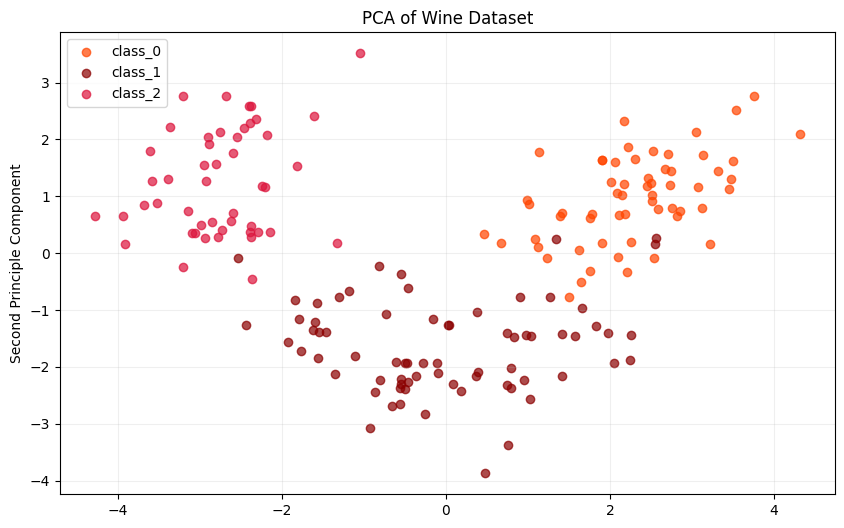

In [24]:
wine_colors=['orangered','darkred','crimson']

plt.figure(figsize=(10,6))

for class_num,color,target_name in zip(
    [0,1,2],wine_colors,target_names
):
    plt.scatter (
        X_reduced[y==class_num,0],
        X_reduced[y==class_num,1],
        color=color,
        label=target_name,
        alpha=0.7
    )

plt.title("PCA of Wine Dataset")
plt.xlabel=("First Principle Component")
plt.ylabel("Second Principle Component")
plt.legend()
plt.grid(alpha=0.2)
plt.show()

In [17]:
print("Prinnnnciple component loadings:")
print(pca.components_)

print("Shape of principal components:",pca.components_.shape)

Prinnnnciple component loadings:
[[ 0.1443294  -0.24518758 -0.00205106 -0.23932041  0.14199204  0.39466085
   0.4229343  -0.2985331   0.31342949 -0.0886167   0.29671456  0.37616741
   0.28675223]
 [ 0.48365155  0.22493093  0.31606881 -0.0105905   0.299634    0.06503951
  -0.00335981  0.02877949  0.03930172  0.52999567 -0.27923515 -0.16449619
   0.36490283]]
Shape of principal components: (2, 13)


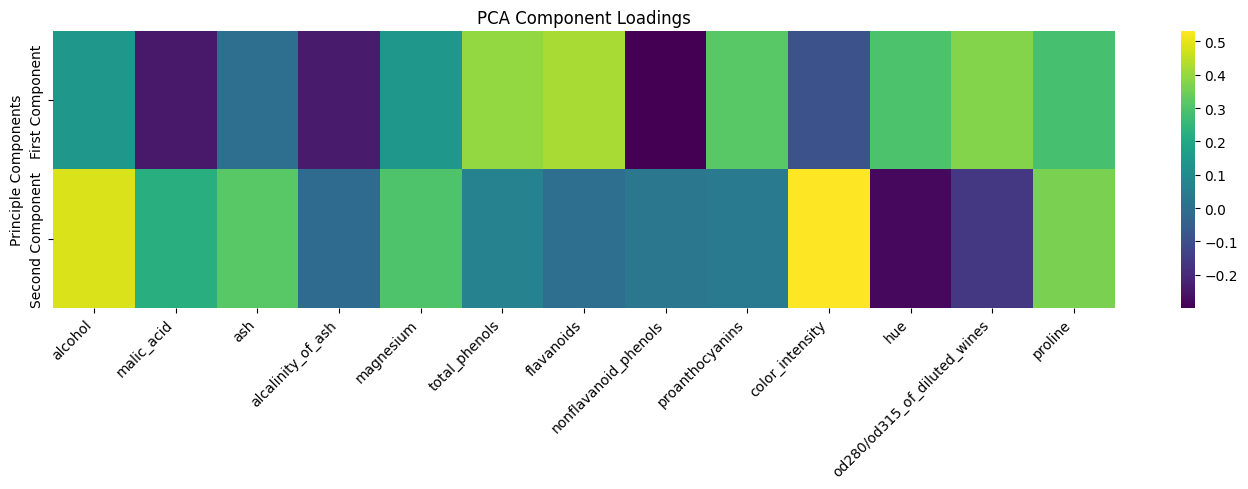

In [25]:
plt.figure(figsize=(14,5))

sns.heatmap(
    pca.components_,
    cmap='viridis',
    xticklabels=feat_names,
    yticklabels=['First Component','Second Component']
)

plt.title('PCA Component Loadings')
plt.xlabel=('Original Features')
plt.ylabel('Principle Components')
plt.xticks(rotation=45, ha ='right')
plt.tight_layout()
plt.show()

In [26]:
print("Explained Variance")
print(pca.explained_variance_)

print("\nExplained variance ratio:")
print(pca.explained_variance_ratio_)



Explained Variance
[4.73243698 2.51108093]

Explained variance ratio:
[0.36198848 0.1920749 ]


In [31]:
pca_3=PCA(n_components=0.96)
X_reduced_96=pca_3.fit_transform(X_scaled)

print("Number of components selected:",pca_3.n_components_)

print("Total explained variance:", np.sum(pca_3.explained_variance_ratio_))
print("Reduced dataset shape:",X_reduced_96.shape)

Number of components selected: 10
Total explained variance: 0.9616971684450643
Reduced dataset shape: (178, 10)


# Random Forest

In [ ]:
# --- Imports ---
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error, r2_score

# --- Loading the data ---
url = (
    "https://archive.ics.uci.edu/ml/"
    "machine-learning-databases/cpu-performance/machine.data"
)

columns = [
    "vendor", "model", "MYCT", "MMIN", "MMAX",
    "CACH", "CHMIN", "CHMAX", "PRP", "ERP"
]

data = pd.read_csv(url, names=columns)

print("First five rows:")
print(data.head())

# --- Shape and missing values ---
print("\nDataset shape:", data.shape)
print("\nMissing values:")
print(data.isnull().sum())

# --- Data visualization ---
data.hist(figsize=(12, 8), bins=15)
plt.tight_layout()
plt.show()

# --- Correlation with PRP ---
correlation = data.select_dtypes(include=np.number).corr()

print("\nCorrelation with PRP:")
print(correlation["PRP"].sort_values(ascending=False))

# --- Correlation heatmap ---
plt.figure(figsize=(10, 7))
sns.heatmap(correlation, annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Correlation Heatmap")
plt.tight_layout()
plt.show()

# --- Features and target ---
# Predict PRP using hardware characteristics
X = data.drop(columns=["PRP", "ERP", "vendor", "model"])
y = data["PRP"]

print("\nFeatures:")
print(X.head())

print("\nTarget:")
print(y.head())

# --- Splitting the data ---
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print("\nTraining samples:", len(X_train))
print("Testing samples:", len(X_test))

# --- Training random forest ---
forest_reg = RandomForestRegressor(
    n_estimators=200,
    random_state=42,
    n_jobs=-1
)

forest_reg.fit(X_train, y_train)

y_train_pred = forest_reg.predict(X_train)

# --- Training results ---
train_rmse = np.sqrt(
    mean_squared_error(y_train, y_train_pred)
)

train_r2 = r2_score(y_train, y_train_pred)

print("\nInitial Training Results")
print("Training RMSE:", round(train_rmse, 2))
print("Training R2 Score:", round(train_r2, 4))